<a href="https://colab.research.google.com/github/oeane26/Telecom_Customer_Churn_Analysis/blob/main/Telecom_Customer_Churn_Analysis.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [6]:
from os import path
from google.colab import drive
drive.mount('/content/drive')

import numpy as np
import matplotlib.pyplot as plt
import pandas as pd
path = '/content/drive/MyDrive/telecom_customer_churn_dataset.csv'
df = pd.read_csv(path)
print(df.head())

  # dataset dimensions
print("Rows:", df.shape[0])
print("Columns:", df.shape[1])

   #Column info
df.info()

Mounted at /content/drive
  customer_id        region               plan contract_type  \
0    CI100000       Abidjan  Postpaid Standard       Monthly   
1    CI100001           Man           Data Max      12-Month   
2    CI100002     San Pedro      Prepaid Basic       Monthly   
3    CI100003  Yamoussoukro      Prepaid Basic       Monthly   
4    CI100004       Abidjan  Postpaid Standard       Monthly   

  acquisition_channel    device_type payment_method  tenure_months  \
0          Mobile App         iPhone   Mobile Money             42   
1        Retail Store        Android   Mobile Money             71   
2        Retail Store  Feature Phone   Mobile Money             52   
3         Call Center        Android   Mobile Money             46   
4          Mobile App         iPhone   Mobile Money             40   

   monthly_data_gb  monthly_voice_minutes  monthly_sms  complaints_last_6m  \
0             5.45                     52           58                 2.0   
1           

In [7]:
missing = df.isnull().sum().sort_values(ascending=False)
print(missing[missing > 0])

service_issue_type     2515
monthly_data_gb          90
monthly_charge_usd       60
acquisition_channel      45
complaints_last_6m       37
dtype: int64


In [8]:
missing_pct = (df.isnull().mean() * 100).sort_values(ascending=False)
print (missing_pct[missing_pct > 0])

service_issue_type     33.533333
monthly_data_gb         1.200000
monthly_charge_usd      0.800000
acquisition_channel     0.600000
complaints_last_6m      0.493333
dtype: float64


In [9]:
df["monthly_data_gb"] = df["monthly_data_gb"].fillna(
    df["monthly_data_gb"].median()
)
df["monthly_charge_usd"] = df["monthly_charge_usd"].fillna(
    df["monthly_charge_usd"].median()
)
df["complaints_last_6m"] = df["complaints_last_6m"].fillna(
    df["complaints_last_6m"].median()
)
df["acquisition_channel"] = df["acquisition_channel"].fillna(
    df["acquisition_channel"].mode()[0]
)

print("Missing values after cleaning:")
print(df.isnull().sum().sum())


Missing values after cleaning:
2515


In [10]:
churn_rate = (df["churned"] == "Yes").mean() * 100
print(f"Overall churn rate: {churn_rate:.2f}%")




Overall churn rate: 11.85%


In [11]:
contract_churn = pd.crosstab(
    df["contract_type"],
    df["churned"],
    normalize="index"
) * 100
print(contract_churn.round(2))

churned           No    Yes
contract_type              
12-Month       89.30  10.70
24-Month       91.04   8.96
6-Month        90.89   9.11
Monthly        86.58  13.42


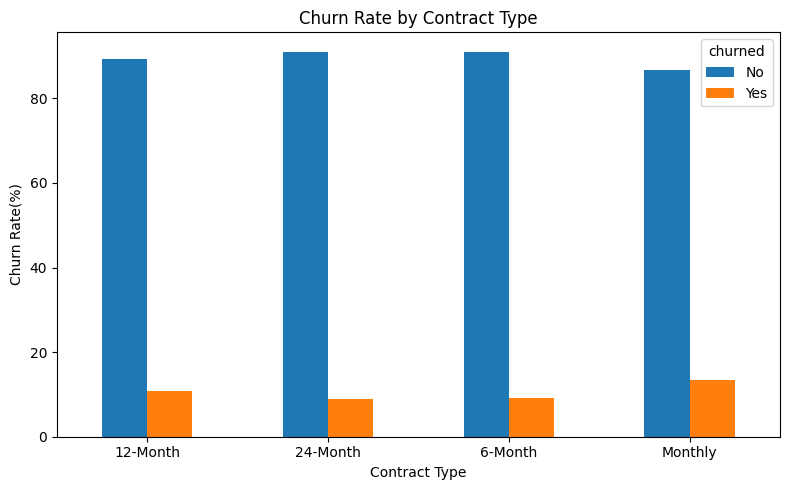

In [12]:
contract_churn.plot(
    kind="bar",
    figsize=(8,5)
)
plt.title("Churn Rate by Contract Type")
plt.xlabel("Contract Type")
plt.ylabel("Churn Rate(%)")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

In [13]:
df["tenure_group"] = pd.cut(
    df["tenure_months"],
    bins=[0, 12, 24, 48, 72, 100],
    labels=["0-12", "13-24", "25-48", "49-72", "73+"]
)
print(df[["tenure_months", "tenure_group"]].head())



tenure_churn = (
    df.groupby("tenure_group", observed=True)["churned"]
      .apply(lambda x: (x =="Yes").mean() *100)
)

print(tenure_churn.round(2))

print (df.columns.tolist())

   tenure_months tenure_group
0             42        25-48
1             71        49-72
2             52        49-72
3             46        25-48
4             40        25-48
tenure_group
0-12     18.05
13-24    15.56
25-48    12.43
49-72     9.29
73+       5.79
Name: churned, dtype: float64
['customer_id', 'region', 'plan', 'contract_type', 'acquisition_channel', 'device_type', 'payment_method', 'tenure_months', 'monthly_data_gb', 'monthly_voice_minutes', 'monthly_sms', 'complaints_last_6m', 'network_incidents_last_6m', 'monthly_charge_usd', 'churned', 'customer_lifetime_value_usd', 'last_90d_revenue_usd', 'service_issue_type', 'tenure_group']


In [14]:
complaint_churn =df.groupby("complaints_last_6m")["churned"].apply(lambda x: (x =="Yes").mean()*100)
print(complaint_churn.round(2))

complaints_last_6m
0.0      8.33
1.0     13.25
2.0     15.24
3.0     22.78
4.0     23.64
5.0     33.33
6.0    100.00
Name: churned, dtype: float64


In [15]:
high_risk = df[
    (df["complaints_last_6m"] >= 2) &
    (df["network_incidents_last_6m"] >= 2) &
    (df["tenure_months"] <= 26)
]

print("High-risk customers:", len(high_risk))

print(
    high_risk[
        [
            "customer_id",
            "region",
            "plan",
            "contract_type",
            "tenure_months",
            "complaints_last_6m",
            "monthly_charge_usd",
            "churned"

        ]
    ].head(10)
)

High-risk customers: 143
    customer_id        region               plan contract_type  tenure_months  \
182    CI100182         Daloa  Postpaid Standard      12-Month             24   
188    CI100188        Bouake       Prepaid Plus       Monthly             24   
218    CI100218  Yamoussoukro       Prepaid Plus       Monthly              2   
246    CI100246       Abidjan      Prepaid Basic      12-Month             18   
257    CI100257     San Pedro           Data Max       Monthly             16   
294    CI100294       Abidjan   Postpaid Premium       Monthly              3   
334    CI100334       Abidjan      Prepaid Basic       Monthly              6   
501    CI100501        Bouake   Postpaid Premium       6-Month             14   
602    CI100602       Abidjan       Prepaid Plus       6-Month             26   
658    CI100658  Yamoussoukro       Prepaid Plus       Monthly              6   

     complaints_last_6m  monthly_charge_usd churned  
182                 2.0      

In [16]:
monthly_revenue_at_risk = high_risk["monthly_charge_usd"].sum()
annual_revenue_at_risk = monthly_revenue_at_risk * 12

print(f"High-risk customers: {len(high_risk)}")
print(f"Monthly revenue associated with high-risk customers: $ {monthly_revenue_at_risk:,.2f}")
print(f"Annualized revenue associated with high-risk customers: $ {annual_revenue_at_risk:,.2f}")




High-risk customers: 143
Monthly revenue associated with high-risk customers: $ 5,626.25
Annualized revenue associated with high-risk customers: $ 67,515.00


In [17]:
high_risk_churn_rate = (
    (high_risk["churned"] == "Yes").mean() * 100
)
print(f"High-risk customer churn rate: {high_risk_churn_rate:.2f}%")

High-risk customer churn rate: 23.78%


In [18]:
other_customers = df[~df.index.isin(high_risk.index)]

other_churn_rate = (
    (other_customers["churned"] == "Yes").mean() * 100
)
print(f"High-risk group churn rate: {high_risk_churn_rate:.2f}%")
print(f"Other customers churn rate: {other_churn_rate:.2f}%")



High-risk group churn rate: 23.78%
Other customers churn rate: 11.62%


In [19]:
risk_multiplier = high_risk_churn_rate / other_churn_rate
print(f"High-risk customer churn {risk_multiplier:.2f}x more than other customers")

High-risk customer churn 2.05x more than other customers


In [20]:
import os
print(os.listdir("/content"))

['.config', 'telecom_customer_churn_dataset.csv', 'drive', 'sample_data']


In [21]:
import pandas as pd
import sqlite3

# EXTRACT
raw_file = "telecom_customer_churn_dataset.csv"

etl_df = pd.read_csv(raw_file)

print("Data extracted successfully!")
print("Rows:", etl_df.shape[0])
print("Columns:", etl_df.shape[1])
etl_df.head()

Data extracted successfully!
Rows: 7500
Columns: 18


,customer_id,region,plan,contract_type,acquisition_channel,device_type,payment_method,tenure_months,monthly_data_gb,monthly_voice_minutes,monthly_sms,complaints_last_6m,network_incidents_last_6m,monthly_charge_usd,churned,customer_lifetime_value_usd,last_90d_revenue_usd,service_issue_type
0,CI100000,Abidjan,Postpaid Standard,Monthly,Mobile App,iPhone,Mobile Money,42,5.45,52,58,2.0,1,68.89,No,2891.94,204.22,Data
1,CI100001,Man,Data Max,12-Month,Retail Store,Android,Mobile Money,71,6.22,77,55,1.0,0,42.89,No,2715.12,130.55,NaN
2,CI100002,San Pedro,Prepaid Basic,Monthly,Retail Store,Feature Phone,Mobile Money,52,8.77,470,51,0.0,1,39.64,No,1853.46,127.39,Data
3,CI100003,Yamoussoukro,Prepaid Basic,Monthly,Call Center,Android,Mobile Money,46,4.34,19,50,0.0,0,43.07,No,2099.25,133.90,NaN
4,CI100004,Abidjan,Postpaid Standard,Monthly,Mobile App,iPhone,Mobile Money,40,3.05,683,53,0.0,2,47.69,No,1771.89,146.18,Billing


In [22]:
print("Duplicate rows:", etl_df.duplicated().sum())
print("Duplicate customer IDs:", etl_df["customer_id"].duplicated().sum())
print("\nMissing values:")
missing_values = etl_df.isnull().sum()
print(missing_values[missing_values > 0])

Duplicate rows: 0
Duplicate customer IDs: 0

Missing values:
acquisition_channel      45
monthly_data_gb          90
complaints_last_6m       37
monthly_charge_usd       60
service_issue_type     2515
dtype: int64


In [23]:
# REMOVE DUPLICATE RECORDS
etl_df = etl_df.drop_duplicates()

etl_df["monthly_data_gb"] = etl_df["monthly_data_gb"].fillna(
    etl_df["monthly_data_gb"].median()
)
etl_df["monthly_charge_usd"] = etl_df["monthly_charge_usd"].fillna(
    etl_df["monthly_charge_usd"].median()
)
etl_df["complaints_last_6m"] = etl_df["complaints_last_6m"].fillna(
    etl_df["complaints_last_6m"].median()
)
etl_df["acquisition_channel"] = etl_df["acquisition_channel"].fillna(
    etl_df["acquisition_channel"].mode()[0]
)

print("Remaining missing values:")
print(etl_df.isnull().sum())





Remaining missing values:
customer_id                       0
region                            0
plan                              0
contract_type                     0
acquisition_channel               0
device_type                       0
payment_method                    0
tenure_months                     0
monthly_data_gb                   0
monthly_voice_minutes             0
monthly_sms                       0
complaints_last_6m                0
network_incidents_last_6m         0
monthly_charge_usd                0
churned                           0
customer_lifetime_value_usd       0
last_90d_revenue_usd              0
service_issue_type             2515
dtype: int64


In [24]:
etl_df["service_issue_type"] = (etl_df["service_issue_type"].fillna("None"))
print("Total missing values:", etl_df.isnull().sum().sum())


Total missing values: 0


In [25]:
etl_df["annualized_revenue_usd"] = (
    etl_df["monthly_charge_usd"] * 12 ).round(2)



etl_df["tenure_group"] = pd.cut(
    etl_df["tenure_months"],
    bins=[0, 12, 24, 48, 72, 100],
    labels=["0-12", "13-24", "25-48", "49-72", "73+"]
)
print(
    etl_df[
        [ "customer_id",
          "monthly_charge_usd",
          "annualized_revenue_usd",
          "tenure_months",
          "tenure_group"]].head())



  customer_id  monthly_charge_usd  annualized_revenue_usd  tenure_months  \
0    CI100000               68.89                  826.68             42   
1    CI100001               42.89                  514.68             71   
2    CI100002               39.64                  475.68             52   
3    CI100003               43.07                  516.84             46   
4    CI100004               47.69                  572.28             40   

  tenure_group  
0        25-48  
1        49-72  
2        49-72  
3        25-48  
4        25-48  


In [26]:
def assign_churn_risk(row):
  score = 0

  if row["tenure_months"] <= 24:
    score += 1

  if row["complaints_last_6m"] >= 2:
    score += 1

  if row["network_incidents_last_6m"] <= 24:
    score += 1

  if row["contract_type"] == "Monthly":
    score += 1

  if score >= 3:
    return "High"
  elif score == 2:
    return "Medium"
  else:
    return "Low"

etl_df["churn_risk"] = etl_df.apply(assign_churn_risk, axis=1)

print(etl_df["churn_risk"].value_counts())


churn_risk
Medium    3683
High      1932
Low       1885
Name: count, dtype: int64


In [27]:
import sqlite3
#create connction to sqlite database
conn = sqlite3.connect("/content/telecom_analytics.db")
etl_df.to_sql(
    "customers",
    conn,
    if_exists="replace",
    index=False

)

print("Data loaded successfuily into SQLite.")

Data loaded successfuily into SQLite.


In [28]:
query = """
SELECT COUNT(*) AS total_customers
FROM customers;
"""
result = pd.read_sql_query(query, conn)
print(result)


   total_customers
0             7500


In [29]:
query = """
SELECT
    customer_id,
    tenure_group,
    churn_risk,
    annualized_revenue_usd
FROM customers
LIMIT 10;
"""
pd.read_sql_query(query, conn)


,customer_id,tenure_group,churn_risk,annualized_revenue_usd
0,CI100000,25-48,High,826.68
1,CI100001,49-72,Low,514.68
2,CI100002,49-72,Medium,475.68
3,CI100003,25-48,Medium,516.84
4,CI100004,25-48,Medium,572.28
5,CI100005,49-72,Medium,269.52
6,CI100006,13-24,High,87.24
7,CI100007,49-72,Medium,568.44
8,CI100008,25-48,High,848.64
9,CI100009,13-24,High,990.24


In [30]:
query = """
SELECT
    churn_risk,
    COUNT(*) AS total_customers,
    SUM (CASE WHEN churned = 'Yes' THEN 1 ELSE 0 END) AS churned_customers,
    ROUND(
          100.0 * SUM( CASE WHEN churned = 'Yes' THEN 1 ELSE 0 END)/ COUNT (*), 2) AS churn_rate_pct, ROUND(SUM(annualized_revenue_usd), 2) AS annualized_revenue_usd
FROM customers
GROUP BY churn_risk
ORDER BY churn_rate_pct DESC;

"""
risk_analysis = pd.read_sql_query(query, conn)
risk_analysis

,churn_risk,total_customers,churned_customers,churn_rate_pct,annualized_revenue_usd
0,High,1932,363,18.79,925401.60
1,Medium,3683,383,10.40,1776001.08
2,Low,1885,143,7.59,911910.96


In [31]:
query = """
SELECT
    region,
    COUNT(*) AS total_customers,
    SUM (CASE WHEN churned = 'Yes' THEN 1 ELSE 0 END) AS churned_customers,
    ROUND(
          100.0 * SUM( CASE WHEN churned = 'Yes' THEN 1 ELSE 0 END)/ COUNT (*), 2) AS churn_rate_pct, ROUND(SUM(annualized_revenue_usd), 2) AS annualized_revenue_usd
FROM customers
GROUP BY region
ORDER BY churn_rate_pct DESC;

"""
region_analysis = pd.read_sql_query(query, conn)
region_analysis

,region,total_customers,churned_customers,churn_rate_pct,annualized_revenue_usd
0,San Pedro,563,71,12.61,263109.48
1,Bouake,884,109,12.33,414869.16
2,Abidjan,3429,421,12.28,1670309.88
3,Korhogo,605,74,12.23,299487.12
4,Daloa,703,85,12.09,336599.76
5,Yamoussoukro,776,81,10.44,366740.16
6,Man,540,48,8.89,262198.08


In [32]:
query = """
SELECT
    contract_type,
    COUNT(*) AS total_customers,
    SUM (CASE WHEN churned = 'Yes' THEN 1 ELSE 0 END) AS churned_customers,
    ROUND(
          100.0 * SUM( CASE WHEN churned = 'Yes' THEN 1 ELSE 0 END)/ COUNT (*), 2) AS churn_rate_pct, ROUND(SUM(annualized_revenue_usd), 2) AS annualized_revenue_usd
FROM customers
GROUP BY contract_type
ORDER BY churn_rate_pct DESC;

"""
contract_analysis = pd.read_sql_query(query, conn)
contract_analysis

,contract_type,total_customers,churned_customers,churn_rate_pct,annualized_revenue_usd
0,Monthly,4233,568,13.42,2033853.60
1,12-Month,1533,164,10.70,742028.16
2,6-Month,1098,100,9.11,536185.08
3,24-Month,636,57,8.96,301246.80


In [33]:
query = """
SELECT
    region,
    contract_type,
    churn_risk,
    COUNT(*) AS total_customers,
    SUM (CASE WHEN churned = 'Yes' THEN 1 ELSE 0 END) AS churned_customers,
    ROUND(
          100.0 * SUM( CASE WHEN churned = 'Yes' THEN 1 ELSE 0 END)/ COUNT (*), 2) AS churn_rate_pct, ROUND(SUM(annualized_revenue_usd), 2) AS annualized_revenue_usd
FROM customers
GROUP BY region,
         contract_type,
         churn_risk
HAVING COUNT(*) >= 30
ORDER BY churn_rate_pct DESC,
        annualized_revenue_usd DESC
LIMIT 15;

"""
segment_analysis = pd.read_sql_query(query, conn)
segment_analysis

,region,contract_type,churn_risk,total_customers,churned_customers,churn_rate_pct,annualized_revenue_usd
0,Bouake,12-Month,Medium,42,11,26.19,20875.44
1,Abidjan,12-Month,High,40,10,25.00,20101.56
2,San Pedro,Monthly,High,145,33,22.76,68660.16
3,Korhogo,Monthly,High,150,31,20.67,75637.56
4,Bouake,Monthly,High,222,44,19.82,104198.40
5,Abidjan,Monthly,High,788,156,19.80,383125.20
6,Daloa,Monthly,High,151,28,18.54,67978.68
7,Man,12-Month,Medium,42,7,16.67,22440.96
8,Yamoussoukro,12-Month,Medium,61,9,14.75,26286.48
9,Abidjan,12-Month,Medium,265,38,14.34,130480.56


In [34]:
query = """
SELECT
    region,
    contract_type,
    churn_risk,
    COUNT(*) AS customers,

    SUM (CASE WHEN churned = 'Yes' THEN 1 ELSE 0 END) AS churned_customers,
    ROUND(
          100.0 * SUM( CASE WHEN churned = 'Yes' THEN 1 ELSE 0 END)/ COUNT (*), 2) AS churn_rate_pct, ROUND(SUM(CASE WHEN churned = 'Yes' THEN annualized_revenue_usd ELSE 0 END), 2) AS revenue_at_risk
FROM customers
GROUP BY region,
         contract_type,
         churn_risk
HAVING COUNT(*) >= 30
ORDER BY revenue_at_risk DESC
LIMIT 15;

"""
priority_segments = pd.read_sql_query(query, conn)
priority_segments

,region,contract_type,churn_risk,customers,churned_customers,churn_rate_pct,revenue_at_risk
0,Abidjan,Monthly,High,788,156,19.80,73221.36
1,Abidjan,Monthly,Medium,1140,116,10.18,58432.20
2,Bouake,Monthly,High,222,44,19.82,20932.80
3,Abidjan,12-Month,Medium,265,38,14.34,20243.16
4,Korhogo,Monthly,High,150,31,20.67,14710.56
5,San Pedro,Monthly,High,145,33,22.76,13786.68
6,Bouake,Monthly,Medium,304,26,8.55,13310.04
7,Abidjan,12-Month,Low,402,25,6.22,12889.80
8,Daloa,Monthly,High,151,28,18.54,12803.04
9,Abidjan,6-Month,Low,287,25,8.71,12692.76


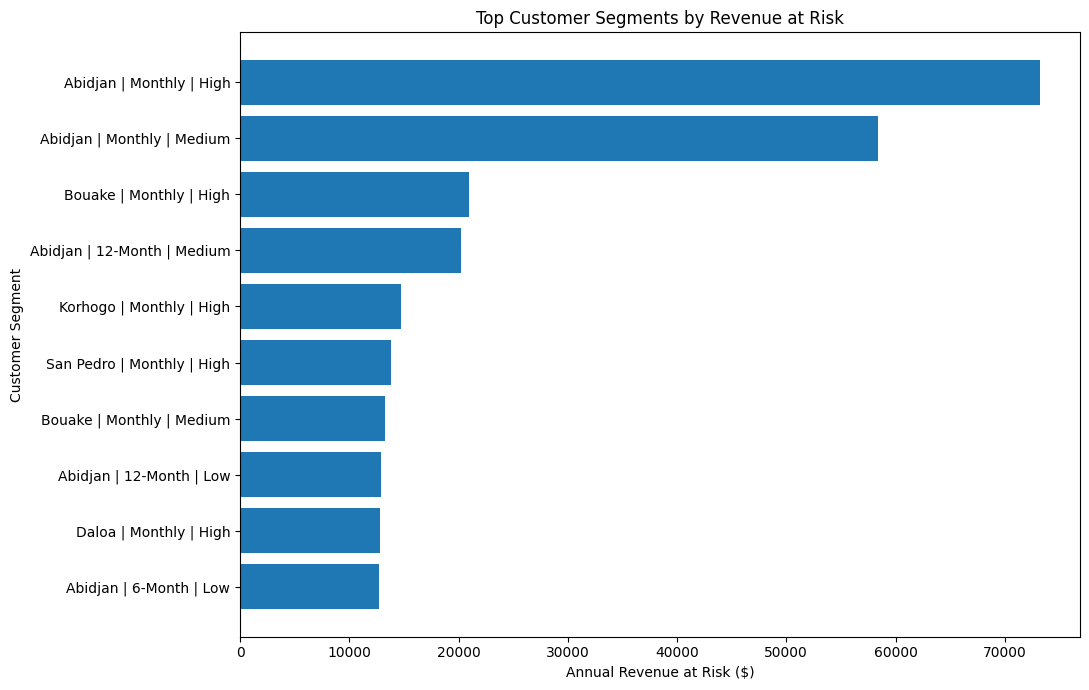

In [35]:
import matplotlib.pyplot as plt
priority_segments["segment"] = (
    priority_segments["region"] +" | " +
    priority_segments["contract_type"] +" | " +
    priority_segments["churn_risk"]

)

top10 = priority_segments.head(10).sort_values("revenue_at_risk", ascending=True)

plt.figure(figsize=(11, 7))
plt.barh(top10["segment"], top10["revenue_at_risk"])
plt.xlabel("Annual Revenue at Risk ($)")
plt.ylabel("Customer Segment")
plt.title("Top Customer Segments by Revenue at Risk")
plt.tight_layout()
plt.show()

In [36]:
region_churn = pd.read_sql_query( """
SELECT
    region,

    COUNT(*) AS total_customers,
    SUM (CASE WHEN churned = 'Yes' THEN 1 ELSE 0 END) AS churned_customers,
    ROUND(
          100.0 * SUM( CASE WHEN churned = 'Yes' THEN 1 ELSE 0 END)/ COUNT (*), 2) AS churn_rate_pct
FROM customers
GROUP BY region


ORDER BY churn_rate_pct DESC;

""", conn)

region_churn

,region,total_customers,churned_customers,churn_rate_pct
0,San Pedro,563,71,12.61
1,Bouake,884,109,12.33
2,Abidjan,3429,421,12.28
3,Korhogo,605,74,12.23
4,Daloa,703,85,12.09
5,Yamoussoukro,776,81,10.44
6,Man,540,48,8.89


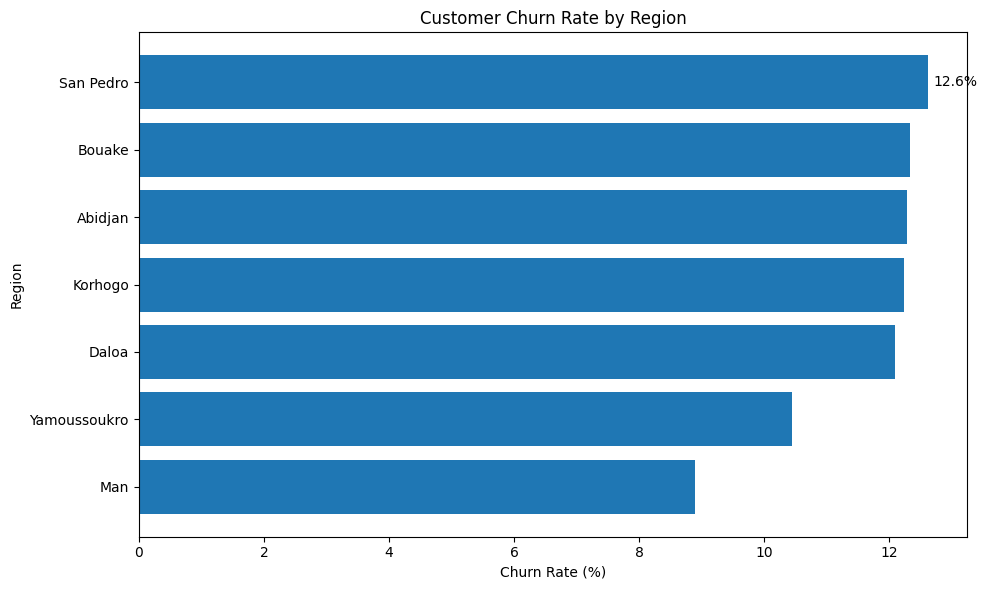

In [37]:


chart_data = region_churn.sort_values("churn_rate_pct", ascending=True)


plt.figure(figsize=(10, 6))

bars = plt.barh(chart_data["region"], chart_data["churn_rate_pct"])


plt.xlabel("Churn Rate (%)")
plt.ylabel("Region")
plt.title("Customer Churn Rate by Region")

for bar in bars:
  width = bar.get_width()

plt.text(width + 0.1, bar.get_y() + bar.get_height()/2, f"{width:.1f}%", va="center")


plt.tight_layout()
plt.show()

In [38]:
kpi_query = """
SELECT
    COUNT(*) AS total_customers,

    SUM (CASE WHEN churned = 'Yes' THEN 1 ELSE 0 END) AS churned_customers,
    ROUND(
          100.0 * SUM( CASE WHEN churned = 'Yes' THEN 1 ELSE 0 END)/ COUNT (*), 2) AS overall_churn_rate, ROUND(SUM(CASE WHEN churned = 'Yes' THEN annualized_revenue_usd ELSE 0 END), 2) AS revenue_at_risk
FROM customers;

"""
executive_kpis = pd.read_sql_query(query, conn)
executive_kpis

,region,contract_type,churn_risk,customers,churned_customers,churn_rate_pct,revenue_at_risk
0,Abidjan,Monthly,High,788,156,19.80,73221.36
1,Abidjan,Monthly,Medium,1140,116,10.18,58432.20
2,Bouake,Monthly,High,222,44,19.82,20932.80
3,Abidjan,12-Month,Medium,265,38,14.34,20243.16
4,Korhogo,Monthly,High,150,31,20.67,14710.56
5,San Pedro,Monthly,High,145,33,22.76,13786.68
6,Bouake,Monthly,Medium,304,26,8.55,13310.04
7,Abidjan,12-Month,Low,402,25,6.22,12889.80
8,Daloa,Monthly,High,151,28,18.54,12803.04
9,Abidjan,6-Month,Low,287,25,8.71,12692.76


In [39]:
high_risk_count= pd.read_sql_query( """
SELECT

    COUNT(*) AS high_risk_customers

FROM customers
WHERE churn_risk = 'High';

""", conn)

high_risk_count

,high_risk_customers
0,1932


In [40]:
executive_summary = pd.read_sql_query("""
SELECT
    COUNT(*) AS total_customers,

    SUM (CASE WHEN churned = 'Yes' THEN 1 ELSE 0 END) AS churned_customers,
    ROUND(
          100.0 * SUM( CASE WHEN churned = 'Yes' THEN 1 ELSE 0 END)/ COUNT (*), 2) AS overall_churn_rate, ROUND(SUM(CASE WHEN churned = 'Yes' THEN annualized_revenue_usd ELSE 0 END), 2) AS revenue_at_risk
FROM customers;

""", conn)
executive_summary

,total_customers,churned_customers,overall_churn_rate,revenue_at_risk
0,7500,889,11.85,430138.08


In [41]:
dashboard_columns = [
            "customer_id",
            "region",
            "plan",
            "contract_type",
            "acquisition_channel",
            "device_type",
            "payment_method",
            "tenure_months",
            "complaints_last_6m",
            "monthly_charge_usd",
            "churned",
            "tenure_group",
            "churn_risk",
            "annualized_revenue_usd",
            "monthly_sms",
            "monthly_voice_minutes",
            "monthly_data_gb",
            "network_incidents_last_6m"
]

dashboard_df = etl_df[dashboard_columns].copy()
dashboard_df.to_csv("/content/telecom_churn_dashboard.csv", index=False)
print("Power BI dataset created created successfully!")
print("Rows:", dashboard_df.shape[0])
print("Columns:", dashboard_df.shape[1])
dashboard_df.head()


Power BI dataset created created successfully!
Rows: 7500
Columns: 18


,customer_id,region,plan,contract_type,acquisition_channel,device_type,payment_method,tenure_months,complaints_last_6m,monthly_charge_usd,churned,tenure_group,churn_risk,annualized_revenue_usd,monthly_sms,monthly_voice_minutes,monthly_data_gb,network_incidents_last_6m
0,CI100000,Abidjan,Postpaid Standard,Monthly,Mobile App,iPhone,Mobile Money,42,2.0,68.89,No,25-48,High,826.68,58,52,5.45,1
1,CI100001,Man,Data Max,12-Month,Retail Store,Android,Mobile Money,71,1.0,42.89,No,49-72,Low,514.68,55,77,6.22,0
2,CI100002,San Pedro,Prepaid Basic,Monthly,Retail Store,Feature Phone,Mobile Money,52,0.0,39.64,No,49-72,Medium,475.68,51,470,8.77,1
3,CI100003,Yamoussoukro,Prepaid Basic,Monthly,Call Center,Android,Mobile Money,46,0.0,43.07,No,25-48,Medium,516.84,50,19,4.34,0
4,CI100004,Abidjan,Postpaid Standard,Monthly,Mobile App,iPhone,Mobile Money,40,0.0,47.69,No,25-48,Medium,572.28,53,683,3.05,2


In [42]:
import os
for folder, subfolders, files in os.walk("/content/drive/MyDrive"):
  for file in files:
    if file.endswith(".csv"):
      print(os.path.join(folder,file))

/content/drive/MyDrive/Automobile (1).csv
/content/drive/MyDrive/telecom_customer_churn_dataset.csv


In [43]:

import pandas as pd
file_path = "/content/drive/MyDrive/telecom_customer_churn_dataset.csv"
dashboard_df = pd.read_csv(file_path)
print(df.head())

  # dataset dimensions
print("Dataset loaded successfully!")
print("Rows:", dashboard_df.shape[0])
print("Columns:", dashboard_df.shape[1])
print(dashboard_df.columns.tolist())

  customer_id        region               plan contract_type  \
0    CI100000       Abidjan  Postpaid Standard       Monthly   
1    CI100001           Man           Data Max      12-Month   
2    CI100002     San Pedro      Prepaid Basic       Monthly   
3    CI100003  Yamoussoukro      Prepaid Basic       Monthly   
4    CI100004       Abidjan  Postpaid Standard       Monthly   

  acquisition_channel    device_type payment_method  tenure_months  \
0          Mobile App         iPhone   Mobile Money             42   
1        Retail Store        Android   Mobile Money             71   
2        Retail Store  Feature Phone   Mobile Money             52   
3         Call Center        Android   Mobile Money             46   
4          Mobile App         iPhone   Mobile Money             40   

   monthly_data_gb  monthly_voice_minutes  monthly_sms  complaints_last_6m  \
0             5.45                     52           58                 2.0   
1             6.22                    

In [44]:
for column in dashboard_df.columns:
  print(column)

customer_id
region
plan
contract_type
acquisition_channel
device_type
payment_method
tenure_months
monthly_data_gb
monthly_voice_minutes
monthly_sms
complaints_last_6m
network_incidents_last_6m
monthly_charge_usd
churned
customer_lifetime_value_usd
last_90d_revenue_usd
service_issue_type


In [45]:
from sklearn.model_selection import train_test_split

# Target: 1 = churned, 0 = stayed
y = dashboard_df["churned"].str.strip().str.lower().map({
    "yes": 1,
    "no": 0
})

# Remove the target, identifier, and potentially
# leakage-prone revenue fields
X = dashboard_df.drop(columns=[
    "churned",
    "customer_id",
    "customer_lifetime_value_usd",
    "last_90d_revenue_usd"
])

# Split data into training and testing sets
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("Training customers:", len(X_train))
print("Testing customers:", len(X_test))
print("Predictor columns:", X.shape[1])
print("Missing target values:", y.isna().sum())

Training customers: 6000
Testing customers: 1500
Predictor columns: 14
Missing target values: 0


In [46]:

from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.impute import SimpleImputer
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import classification_report, roc_auc_score

# Identify numerical and categorical columns
numeric_cols = X_train.select_dtypes(include="number").columns.tolist()
categorical_cols = X_train.select_dtypes(exclude="number").columns.tolist()

# Prepare numerical data
numeric_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])

# Prepare categorical data
categorical_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("encoder", OneHotEncoder(handle_unknown="ignore"))
])

# Combine preprocessing steps
preprocessor = ColumnTransformer([
    ("numeric", numeric_pipeline, numeric_cols),
    ("categorical", categorical_pipeline, categorical_cols)
])

# Build and train model
logistic_model = Pipeline([
    ("preprocessing", preprocessor),
    ("classifier", LogisticRegression(
        max_iter=1000,
        class_weight="balanced",
        random_state=42
    ))
])

logistic_model.fit(X_train, y_train)

# Evaluate on unseen test data
predictions = logistic_model.predict(X_test)
probabilities = logistic_model.predict_proba(X_test)[:, 1]

print("LOGISTIC REGRESSION RESULTS")
print(classification_report(y_test, predictions, zero_division=0))
print("ROC-AUC:", round(roc_auc_score(y_test, probabilities), 4))


LOGISTIC REGRESSION RESULTS
              precision    recall  f1-score   support

           0       0.92      0.65      0.76      1322
           1       0.18      0.58      0.28       178

    accuracy                           0.64      1500
   macro avg       0.55      0.62      0.52      1500
weighted avg       0.83      0.64      0.70      1500

ROC-AUC: 0.6644


In [47]:

from sklearn.ensemble import RandomForestClassifier

# Build Random Forest model
random_forest_model = Pipeline([
    ("preprocessing", preprocessor),
    ("classifier", RandomForestClassifier(
        n_estimators=200,
        max_depth=10,
        min_samples_leaf=5,
        class_weight="balanced",
        random_state=42,
        n_jobs=-1
    ))
])

# Train model
random_forest_model.fit(X_train, y_train)

# Make predictions
rf_predictions = random_forest_model.predict(X_test)
rf_probabilities = random_forest_model.predict_proba(X_test)[:, 1]

# Evaluate model
print("RANDOM FOREST RESULTS")
print(classification_report(
    y_test, rf_predictions, zero_division=0
))
print("ROC-AUC:", round(
    roc_auc_score(y_test, rf_probabilities), 4
))


RANDOM FOREST RESULTS
              precision    recall  f1-score   support

           0       0.89      0.91      0.90      1322
           1       0.23      0.20      0.21       178

    accuracy                           0.83      1500
   macro avg       0.56      0.55      0.56      1500
weighted avg       0.82      0.83      0.82      1500

ROC-AUC: 0.6369


In [48]:
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler

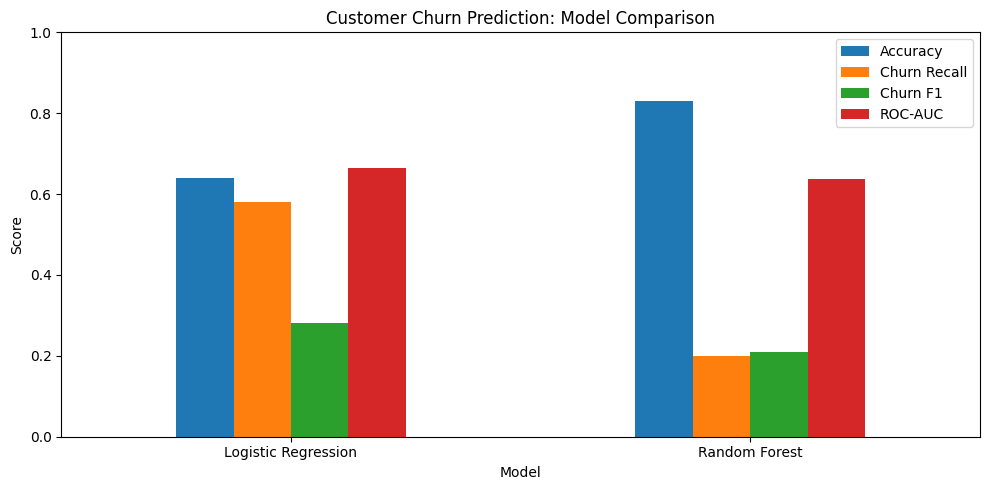

In [49]:

import matplotlib.pyplot as plt
import pandas as pd

comparison = pd.DataFrame({
    "Model": ["Logistic Regression", "Random Forest"],
    "Accuracy": [0.64, 0.83],
    "Churn Recall": [0.58, 0.20],
    "Churn F1": [0.28, 0.21],
    "ROC-AUC": [0.6644, 0.6369]
})

comparison.set_index("Model").plot(
    kind="bar",
    figsize=(10, 5),
    rot=0
)

plt.title("Customer Churn Prediction: Model Comparison")
plt.ylabel("Score")
plt.ylim(0, 1)
plt.legend(loc="upper right")
plt.tight_layout()
plt.show()


In [50]:

print("MODEL PREDICTOR COLUMNS")
for column in X_train.columns:
    print(column)

print("\nCHURN DISTRIBUTION")
print(y_train.value_counts())


MODEL PREDICTOR COLUMNS
region
plan
contract_type
acquisition_channel
device_type
payment_method
tenure_months
monthly_data_gb
monthly_voice_minutes
monthly_sms
complaints_last_6m
network_incidents_last_6m
monthly_charge_usd
service_issue_type

CHURN DISTRIBUTION
churned
0    5289
1     711
Name: count, dtype: int64


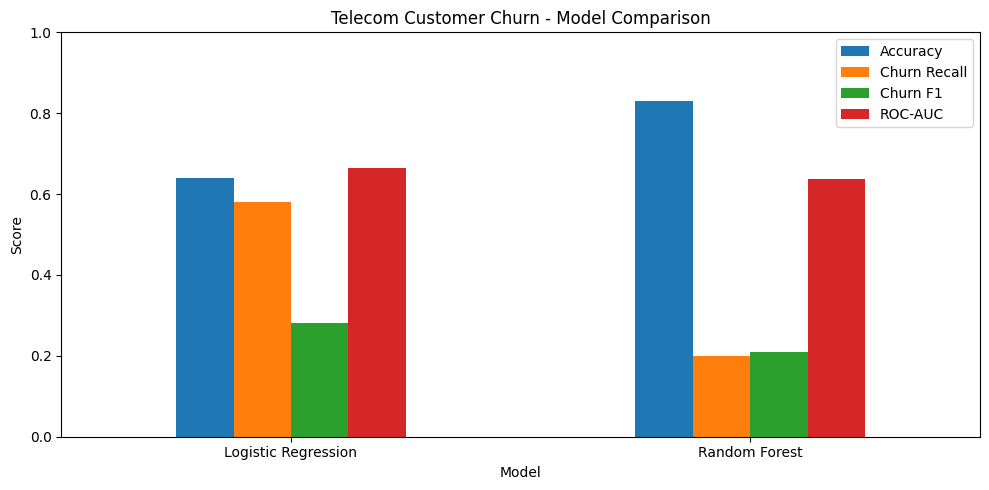

Chart saved successfully!


In [51]:

import matplotlib.pyplot as plt

comparison.set_index("Model").plot(
    kind="bar",
    figsize=(10, 5),
    rot=0
)

plt.title("Telecom Customer Churn - Model Comparison")
plt.ylabel("Score")
plt.ylim(0, 1)
plt.tight_layout()

plt.savefig(
    "/content/model_comparison.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

print("Chart saved successfully!")


In [52]:

import os
import matplotlib.pyplot as plt

folder = "/content/drive/MyDrive/Telecom_Churn_Portfolio"
os.makedirs(folder, exist_ok=True)

# Find the chart file if it was saved under another name
for root, dirs, files in os.walk("/content"):
    if root.startswith("/content/drive"):
        continue
    for file in files:
        if file.lower().endswith(".png"):
            print(os.path.join(root, file))


/content/model_comparison.png


In [53]:

import os
import shutil

source = "/content/model_comparison.png"
destination = "/content/drive/MyDrive/Telecom_Churn_Portfolio"

os.makedirs(destination, exist_ok=True)

shutil.copy2(source, destination)

print("SUCCESS! Chart saved to Google Drive!")
print(os.listdir(destination))


SUCCESS! Chart saved to Google Drive!
['model_comparison.png']
